# Arbeitspaket (AP) 5: Datenbeschaffung, Datenaufbereitung & explorative Datenanalyse

### Persönliche Angaben (bitte ergänzen) und Prüfungsregeln

<table>
  <tr><td>Vorname:</td><td></td></tr>
  <tr><td>Nachname:</td><td></td></tr>
  <tr><td>Immatrikulationsnummer:</td><td></td></tr>
  <tr><td>Modul:</td><td>Data Science</td></tr>
  <tr><td>Prüfungsdatum / Raum / Zeit:</td><td>[TT.MM.2026] / Raum: [anpassen] / [hh:mm – hh:mm]</td></tr>
  <tr><td>Erlaubte Hilfsmittel:</td><td>Es gelten die Prüfungsregeln (PDF-Dokument auf EXAM-Moodle).</td></tr>
  <tr><td>Nicht erlaubt:</td><td>Es gelten die Prüfungsregeln (PDF-Dokument auf EXAM-Moodle).</td></tr>
  <tr><td>Technische Probleme:</td><td>Wenden Sie sich bei technischen Problemen umgehend an die Prüfungsaufsicht.</td></tr>
</table>

## Bewertungskriterien

**(max. erreichbare Punkte: 40)**

<table>
  <thead>
    <tr><th>Teil</th><th>Thema</th><th>Aufgaben</th><th>Punkte</th></tr>
  </thead>
  <tbody>
    <tr><td>A</td><td>Konzeptfragen: Datenaufbereitung &amp; explorative Datenanalyse</td><td>A1–A3</td><td>12</td></tr>
    <tr><td>B</td><td>Fehleranalyse Python-Code (Shop-Daten)</td><td>B1–B2</td><td>16</td></tr>
    <tr><td>C</td><td>Python-Code schreiben: Web Scraping, Datenaufbereitung &amp; EDA</td><td>C1–C3</td><td>12</td></tr>
    <tr><td><b>Total</b></td><td></td><td><b>8 Aufgaben</b></td><td><b>40</b></td></tr>
  </tbody>
</table>

### Bewertungsschema

Jede Aufgabe wird für sich und **als Ganzes** bewertet. Ihre Punktzahl steht in der Überschrift.

<table>
  <thead>
    <tr><th>Kategorie</th><th>Beschreibung</th><th>Bewertung</th><th>4 Pkt</th><th>8 Pkt</th></tr>
  </thead>
  <tbody>
    <tr><td>Korrekt</td><td>Vollständig und fachlich einwandfrei: Antwort bzw. Begründung korrekt und nachvollziehbar; bei Code-Aufgaben liefert der Python-Code das richtige Ergebnis</td><td>100%</td><td>4</td><td>8</td></tr>
    <tr><td>Minimale Mängel</td><td>Kleine Fehler (z.B. falsche Sortierung, fehlende Rundung, fehlende Achsenbeschriftung) oder Begründung ungenau bzw. unvollständig</td><td>75%</td><td>3</td><td>6</td></tr>
    <tr><td>Mittlere Mängel</td><td>Grössere Fehler (z.B. fehlende Spalten, falsche Filterung) oder Begründung fehlt bzw. ist fachlich falsch</td><td>50%</td><td>2</td><td>4</td></tr>
    <tr><td>Gravierende Mängel</td><td>Problem bzw. Ansatz erkennbar, aber Lösung oder Schlussfolgerung im Kern falsch (z.B. Problem richtig benannt, aber falsch behoben; im Code: ungeeigneter Lösungsweg wie falscher Join-Typ, falsche Tabelle oder falsche Datei)</td><td>25%</td><td>1</td><td>2</td></tr>
    <tr><td>Nicht lauffähig / nicht sinnvoll</td><td>Antwort fehlt, Code nicht lauffähig (z.B. Syntaxfehler) oder kein Bezug zur Aufgabe</td><td>0%</td><td>0</td><td>0</td></tr>
  </tbody>
</table>

Treffen mehrere Mängel zusammen, zählt der schwerste. Alternative, fachlich korrekte Lösungswege werden ebenfalls als korrekt gewertet.

## Hinweise zu den Daten

Alle Daten stammen vom **fiktiven** Schweizer Online-Shop «PhoneMarkt» und liegen **lokal** im gleichen Verzeichnis wie dieses Notebook. Für die Prüfung ist **kein Internetzugriff** auf Websites oder APIs nötig.

<table>
  <thead>
    <tr><th>Datei</th><th>Format</th><th>Inhalt</th></tr>
  </thead>
  <tbody>
    <tr><td><code>html/shop_page_1.html</code> … <code>shop_page_3.html</code></td><td>HTML</td><td>Gespeicherte Produktlisten-Seiten (3 Seiten mit Paginierung)</td></tr>
    <tr><td><code>html/product_detail.html</code></td><td>HTML</td><td>Gespeicherte Detailseite eines Geräts (Preisverlauf, technische Daten)</td></tr>
    <tr><td><code>reviews.json</code></td><td>JSON</td><td>Gespeicherte Antwort der Reviews-API: Liste mit Kundenbewertungen pro <code>product_id</code></td></tr>
    <tr><td><code>smartphones_clean.csv</code></td><td>CSV</td><td>Aufbereitete Shop-Daten: Formate vereinheitlicht, Duplikate entfernt — <b>inhaltlich nicht geprüft</b></td></tr>
  </tbody>
</table>

Die Spaltenbeschreibungen finden Sie im Sheet **«Description»**, die Datenquellen im Sheet **«Data Sources»** der beiliegenden Datei `smartphone_data.xlsx`. Die HTML-Dateien können Sie zur Ansicht auch im Browser oder als Text im Editor öffnen.

**Antworten auf Konzeptfragen** und **Begründungen** tragen Sie bitte direkt in die vorgesehenen Markdown-Zellen ein.

## Setup (wird nicht bewertet)

In [1]:
# Libraries
import os
import re
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Get current working directory
print(os.getcwd())

/Users/m/projects/DS_HS2026_LNW/DS_HS2026_LNW_I_Examples/AP05


### Produktlisten-Seiten scrapen → `df_raw`

Der folgende Code liest die drei gespeicherten Produktlisten-Seiten mit BeautifulSoup ein (analog zur Übung `skipass_data.ipynb`). Jede Produktkarte (`<div class="product-card">`) wird zu einer Zeile im Data Frame `df_raw`. Die Werte werden **als Text** übernommen (Spalten mit Endung `_raw`) und noch nicht bereinigt.

In [2]:
# Initialize list for the extracted rows
rows = []

# Loop over the three listing pages
for page in [1, 2, 3]:

    # Read html from file
    with open(f'html/shop_page_{page}.html', 'r', encoding='utf-8') as file:
        html_content = file.read()

    # Parse the HTML content
    soup = BeautifulSoup(html_content, 'html.parser')

    # Locate the product cards and extract values
    for card in soup.select('div.product-card'):
        row_data = [card['data-product-id'],
                    card.select('span.brand')[0].get_text().replace('\xa0', '').strip(),
                    card.select('span.model')[0].get_text().replace('\xa0', '').strip(),
                    card.select('li.storage')[0].get_text().replace('\xa0', '').strip(),
                    card.select('li.color')[0].get_text().replace('\xa0', '').strip(),
                    card.select('li.screen')[0].get_text().replace('\xa0', '').strip(),
                    card.select('li.battery')[0].get_text().replace('\xa0', '').strip(),
                    card.select('span.price')[0].get_text().replace('\xa0', '').strip(),
                    card.select('span.availability')[0].get_text().replace('\xa0', '').strip()]
        rows.append(row_data)

# Create a DataFrame
df_raw = pd.DataFrame(rows, columns=['product_id', 'brand', 'model', 'storage_raw', 'color',
                                     'screen_raw', 'battery_raw', 'price_raw', 'availability'])

# Show dimensions and first rows
print('Number of rows and columns:', df_raw.shape)
df_raw.head()

Number of rows and columns: (148, 9)


,product_id,brand,model,storage_raw,color,screen_raw,battery_raw,price_raw,availability
0,PM-10001,Xiaomi,Redmi Note 14 Pro 5G,256GB,Midnight Black,"6.67"" Display",5'110mAh,CHF 299.–,Sofort lieferbar
1,PM-10002,OnePlus,OnePlus 13,256GB,Arctic Dawn,"6.82"" Display",6'000mAh,CHF 899.–,Lieferbar in 2–5 Tagen
2,PM-10003,Google,Pixel 10 Pro,512GB,Obsidian,"6.3"" Display",4'870mAh,CHF 1'249.–,Sofort lieferbar
3,PM-10004,Samsung,Galaxy A36 5G,128GB,Awesome Lavender,"6.7"" Display",5'000mAh,CHF 339.–,Sofort lieferbar
4,PM-10005,Samsung,Galaxy Z Fold7,1TB,Jetblack,"8.0"" Display",4'400mAh,Preis auf Anfrage,Vorbestellung


### Aufbereitete Shop-Daten laden → `df_clean`

In [3]:
# Import data from csv to pandas dataframe named 'df_clean'
df_clean = pd.read_csv('smartphones_clean.csv')

# Show dimensions and first rows
print('Number of rows and columns:', df_clean.shape)
df_clean.head()

Number of rows and columns: (142, 9)


,product_id,brand,model,storage_gb,color,screen_inch,battery_mah,price_chf,availability
0,PM-10001,Xiaomi,Redmi Note 14 Pro 5G,256,Midnight Black,6.67,5110,299.0,Sofort lieferbar
1,PM-10002,OnePlus,OnePlus 13,256,Arctic Dawn,6.82,6000,899.0,Lieferbar in 2–5 Tagen
2,PM-10003,Google,Pixel 10 Pro,512,Obsidian,6.30,4870,1249.0,Sofort lieferbar
3,PM-10004,Samsung,Galaxy A36 5G,128,Awesome Lavender,6.70,5000,339.0,Sofort lieferbar
4,PM-10005,Samsung,Galaxy Z Fold7,1024,Jetblack,8.00,4400,NaN,Vorbestellung


> **Hinweis:** Alle Aufgaben sind voneinander unabhängig. Verändern Sie `df_raw` und `df_clean` bitte nicht direkt, sondern arbeiten Sie in jeder Aufgabe mit einem eigenen Data Frame (z.B. `df_B1`, `df_C2`).

---

<div style="background-color:#2E4057; color:white; padding:16px 24px; border-radius:6px; font-size:18px; margin-top:8px;">
&#9654;&nbsp; <strong>Ab hier beginnt die bewertete Prüfung — 40 Punkte</strong><br>
<span style="font-size:15px; font-weight:normal;">Tragen Sie Ihre Antworten direkt in die vorgesehenen Zellen ein und führen Sie alle Code-Zellen aus.</span>
</div>

---
## Teil A – Konzeptfragen (12 Punkte)

*Antworten ohne Bezug zu den Shop-Daten von «PhoneMarkt» werden nicht gewertet.*

### A1 (4 Punkte)

Die gescrapten Rohdaten `df_raw` enthalten 148 Zeilen, der Shop führt aber nur 142 Artikel. Ein Kollege entfernt die Duplikate wie folgt:

```python
df_dedup = df_raw.drop_duplicates(subset=['brand', 'model'])
df_dedup.shape          # Ergebnis: (33, 9)
```

a) Warum ist dieses Vorgehen falsch? Begründen Sie mit den Shop-Daten.

b) Wie entstehen die Duplikate in `df_raw`, und wie entfernt man sie korrekt?

**Ihre Antwort:**

> 

In [117]:
df_raw.info

<bound method DataFrame.info of     product_id    brand                 model storage_raw             color  \
0     PM-10001   Xiaomi  Redmi Note 14 Pro 5G       256GB    Midnight Black   
1     PM-10002  OnePlus            OnePlus 13       256GB       Arctic Dawn   
2     PM-10003   Google          Pixel 10 Pro       512GB          Obsidian   
3     PM-10004  Samsung         Galaxy A36 5G       128GB  Awesome Lavender   
4     PM-10005  Samsung        Galaxy Z Fold7         1TB          Jetblack   
..         ...      ...                   ...         ...               ...   
143   PM-10138  Samsung            Galaxy S25       256GB              Mint   
144   PM-10139  Samsung         Galaxy A36 5G       128GB     Awesome Black   
145   PM-10140   Google     Pixel 10 Pro Fold       512GB         Moonstone   
146   PM-10141    Apple         iPhone 17 Pro       256GB            Silver   
147   PM-10142    Apple            iPhone 16e       128GB             White   

        screen_raw 

### A2 (4 Punkte)

Ordnen Sie die drei Variablen `brand`, `availability` (`Sofort lieferbar`, `Lieferbar in 2–5 Tagen`, `Vorbestellung`) und `battery_mah` jeweils einem **Skalenniveau** zu (nominal, ordinal, metrisch). Nennen Sie für jede Variable ein **zulässiges Lagemass** (Modus, Median oder Mittelwert) und eine geeignete **univariate Grafik**. Begründen Sie kurz.

**Ihre Antwort:**

> [Hier eintragen]

### A3 (4 Punkte)

Für ein späteres Machine-Learning-Modell sollen die metrischen Variablen skaliert werden. In `df_clean` gilt:

```
               min       max      mean
battery_mah   3149      7000   4793.39
price_chf      159     12990    992.89
```

a) Berechnen Sie **per Hand** den Min-Max-skalierten Wert (Bereich 0–1) eines Geräts mit **5'000 mAh**. Geben Sie den Rechenweg an.

b) Warum ist Min-Max-Scaling für `price_chf` problematisch? Nennen Sie eine geeignetere Skalierungsmethode.

**Ihre Antwort:**

> [Hier eintragen]

---
## Teil B – Fehleranalyse Python-Code (16 Punkte)

*Jeder Code läuft fehlerfrei durch, liefert aber ein falsches oder irreführendes Ergebnis. Die tatsächlichen Ergebnisse sind angegeben.*

In [ ]:
df_clean = pd.read_csv('/Users/m/projects/DS_HS2026_LNW/DS_HS2026_LNW_I_Examples/AP05/smartphones_clean.csv', sep=',', encoding='utf-8', # 'latin-1' if umlauts broken
 decimal='.', thousands="'", na_values=['', 'n/a'])
 
from IPython.display import HTML # whole df in a scrollable box
HTML(f'<div style="max-height:400px; overflow:auto">{df_B1.to_html()}</div>') 

,product_id,brand,model,storage_raw,screen_raw,storage_gb,screen_inch
0,PM-10001,Xiaomi,Redmi Note 14 Pro 5G,256GB,"6.67"" Display",256,6
1,PM-10002,OnePlus,OnePlus 13,256GB,"6.82"" Display",256,6
2,PM-10003,Google,Pixel 10 Pro,512GB,"6.3"" Display",512,6
3,PM-10004,Samsung,Galaxy A36 5G,128GB,"6.7"" Display",128,6
4,PM-10005,Samsung,Galaxy Z Fold7,1TB,"8.0"" Display",1,8
5,PM-10006,Xiaomi,Redmi Note 14 Pro 5G,256GB,"6.67"" Display",256,6
6,PM-10007,Google,Pixel 10 Pro,256GB,"6.3"" Display",256,6
7,PM-10008,Sony,Xperia 1 VII,512GB,"6.5"" Display",512,6
8,PM-10009,Motorola,edge 60,256GB,"6.67"" Display",256,6
9,PM-10010,Motorola,moto g75 5G,256GB,"6.78"" Display",256,6


### B1 (8 Punkte)

**Ziel:** Technische Kennzahlen des Sortiments aus den gescrapten Rohdaten `df_raw`: mittlere Speicherkapazität in GB, mittlere Bildschirmdiagonale in Zoll und Anzahl Geräte mit mindestens 1 TB Speicher.

```python
# Select columns for the analysis, remove duplicated values and reset the index
df_B1 = df_raw[['product_id', 'brand', 'model', 'storage_raw', 'screen_raw']].drop_duplicates().reset_index(drop=True)

# Extract numerical values from storage_raw
storage = []
for i in df_B1['storage_raw']:
    d1 = re.findall(r"\d+", i)
    storage.append(int(d1[0]))

# Extract numerical values from screen_raw
screen = []
for i in df_B1['screen_raw']:
    d1 = re.findall(r"\d+", i)
    screen.append(int(d1[0]))

# Save as new variables in the pandas data frame
df_B1['storage_gb'] = storage
df_B1['screen_inch'] = screen

# Show key figures
print('Anzahl Geräte:                ', df_B1.shape[0])
print('Mittlere Speicherkapazität (GB):', round(df_B1['storage_gb'].mean(), 1))
print('Mittlere Bildschirmdiagonale:   ', round(df_B1['screen_inch'].mean(), 2))
print('Geräte mit mind. 1 TB:          ', (df_B1['storage_gb'] >= 1024).sum())
```

Tatsächliches Ergebnis:

```
Anzahl Geräte:                 142
Mittlere Speicherkapazität (GB): 277.8
Mittlere Bildschirmdiagonale:    6.18
Geräte mit mind. 1 TB:           0
```

Beispiele für Werte: `storage_raw` = `128GB`, `256GB`, `1TB`; `screen_raw` = `6.3" Display`, `6.67" Display`. Laut Sheet «Description» gilt 1 TB = 1024 GB.

**Aufgabe:** Schreiben Sie den korrigierten Code in die Zelle «Korrigierter Code» (die Kommentare des ursprünglichen Codes sind als Gerüst vorgegeben), sodass die Kennzahlen stimmen. Begründen Sie jede Änderung gegenüber dem ursprünglichen Code.

**Begründung der Änderungen:**

> erster Regex: die TB angaben wurden als GB behandelt, deshalb musste zuerst umgerechnet werden.

> zweiter regex: Hat nur die erste Zahl eines Floats aufgenommen. Floats werden nun korrekt erkannt.

> bei beiden Ausgaben führt das dazu, dass die Mittelwerte häher sind.

**Korrigierter Code:**

In [23]:
FLOAT = r'-?\d+(?:[.,]\d+)?'
# Korrigierten Code unter den Kommentaren eintragen

# Select columns for the analysis, remove duplicated values and reset the index
df_B1 = df_raw[['product_id', 'brand', 'model', 'storage_raw', 'screen_raw']].drop_duplicates().reset_index(drop=True)

# Extract numerical values from storage_raw
storage = []
for i in df_B1['storage_raw']:
    d1 = re.findall(r"\d+", i)
    d1 = int(d1[0])
    if d1 <= 100:
        d1 = d1 * 1024
    storage.append(d1)

# Extract numerical values from screen_raw
screen = []
for i in df_B1['screen_raw']:
    d1 = re.findall(FLOAT, i)
    screen.append(float(d1[0]))

# Save as new variables in the pandas data frame
df_B1['storage_gb'] = storage
df_B1['screen_inch'] = screen

# Show key figures
print('Anzahl Geräte:                ', df_B1.shape[0])
print('Mittlere Speicherkapazität (GB):', round(df_B1['storage_gb'].mean(), 1))
print('Mittlere Bildschirmdiagonale:   ', round(df_B1['screen_inch'].mean(), 2))
print('Geräte mit mind. 1 TB:          ', (df_B1['storage_gb'] >= 1024).sum())

Anzahl Geräte:                 142
Mittlere Speicherkapazität (GB): 407.4
Mittlere Bildschirmdiagonale:    6.7
Geräte mit mind. 1 TB:           18


### B2 (8 Punkte)

**Ziel:** Für welche Marken fehlen noch Kundenbewertungen? Gesucht ist der **Anteil der Geräte ohne Kundenbewertung** pro Marke in Prozent (Basis: alle Geräte in `df_clean`).

```python
# Read the customer reviews
df_reviews = pd.read_json('reviews.json')

# Join the reviews to the shop data
df_B2 = df_clean.merge(df_reviews, on='product_id')

# Flag devices without reviews
df_B2['no_review'] = df_B2['review_count'].isnull()

# Share of devices without reviews per brand (in %)
print('Anzahl Geräte:', df_B2.shape[0])
(df_B2.groupby('brand')['no_review'].mean() * 100).round(1).sort_values(ascending=False)
```

Tatsächliches Ergebnis:

```
Anzahl Geräte: 124
brand
Apple        0.0
Fairphone    0.0
Google       0.0
Motorola     0.0
Nothing      0.0
OnePlus      0.0
Samsung      0.0
Sony         0.0
Xiaomi       0.0
Name: no_review, dtype: float64
```

Der Produktmanager widerspricht: *«Gerade bei den neuen iPhone- und Pixel-Modellen gibt es noch kaum Bewertungen.»*

**Aufgabe:** Schreiben Sie den korrigierten Code in die Zelle «Korrigierter Code» (die Kommentare des ursprünglichen Codes sind als Gerüst vorgegeben). Begründen Sie jede Änderung gegenüber dem ursprünglichen Code und erklären Sie, warum ein `how='outer'` hier ebenfalls nicht korrekt wäre.

**Begründung der Änderungen:**

> [Hier eintragen]

**Korrigierter Code:**

In [37]:
# Read the customer reviews
df_reviews = pd.read_json('reviews.json')

# Join the reviews to the shop data
df_B2 = df_clean.merge(df_reviews, on='product_id', how='left')

# Flag devices without reviews
df_B2['no_review'] = df_B2['review_count'].isna()

# Share of devices without reviews per brand (in %)
print('Anzahl Geräte:', df_B2.shape[0])
(df_B2.groupby('brand')['no_review'].mean() * 100).round(1).sort_values(ascending=False)

Anzahl Geräte: 142


brand
Nothing      25.0
Apple        23.5
Sony         16.7
Google       15.4
Xiaomi       11.1
Samsung       2.9
Fairphone     0.0
Motorola      0.0
OnePlus       0.0
Name: no_review, dtype: float64

In [29]:
from IPython.display import HTML # whole df in a scrollable box
HTML(f'<div style="max-height:400px; overflow:auto">{df_B2.to_html()}</div>') 

,product_id,brand,model,storage_gb,color,screen_inch,battery_mah,price_chf,availability,review_count,avg_score,no_review
0,PM-10001,Xiaomi,Redmi Note 14 Pro 5G,256,Midnight Black,6.67,5110,299.0,Sofort lieferbar,133,3.0,False
1,PM-10002,OnePlus,OnePlus 13,256,Arctic Dawn,6.82,6000,899.0,Lieferbar in 2–5 Tagen,135,4.1,False
2,PM-10003,Google,Pixel 10 Pro,512,Obsidian,6.30,4870,1249.0,Sofort lieferbar,10,4.3,False
3,PM-10004,Samsung,Galaxy A36 5G,128,Awesome Lavender,6.70,5000,339.0,Sofort lieferbar,92,3.2,False
4,PM-10005,Samsung,Galaxy Z Fold7,1024,Jetblack,8.00,4400,NaN,Vorbestellung,63,3.7,False
5,PM-10006,Xiaomi,Redmi Note 14 Pro 5G,256,Ocean Blue,6.67,5110,299.0,Sofort lieferbar,75,3.3,False
6,PM-10007,Google,Pixel 10 Pro,256,Obsidian,6.30,4870,989.0,Lieferbar in 2–5 Tagen,47,3.7,False
7,PM-10008,Sony,Xperia 1 VII,512,Moss Green,6.50,5000,1549.0,Sofort lieferbar,80,4.2,False
8,PM-10009,Motorola,edge 60,256,Gibraltar Sea,6.67,5200,379.0,Sofort lieferbar,10,3.0,False
9,PM-10010,Motorola,moto g75 5G,256,Aqua Blue,6.78,5000,249.0,Vorbestellung,38,2.8,False


---
## Teil C – Python-Code schreiben (12 Punkte)

Schreiben Sie Python-Code und begründen Sie Ihre Vorgehensweise jeweils in 1–2 Sätzen. Worauf die Begründung eingehen soll, steht bei der Aufgabe.

### C1 (4 Punkte)

Einige Produktkarten zeigen zusätzlich einen durchgestrichenen **Streichpreis** (`<span class="price-old"><del>CHF 1'099.–</del></span>`), die meisten aber nicht. In der Code-Zelle ist ein Gerüst vorgegeben, das die drei Produktlisten-Seiten einliest, die Duplikate entfernt und die Preistexte in Zahlen umwandelt.

Ergänzen Sie die beiden mit `# TODO` markierten Stellen:

1. Lesen Sie den Streichpreis als Text aus — bzw. `None`, wenn die Karte keinen Streichpreis hat.
2. Berechnen Sie den Rabatt in Prozent des Streichpreises (neue Spalte `discount_pct`).

Begründen Sie, wie Sie mit Karten **ohne** Streichpreis umgehen und warum das nötig ist.

*Tipp: Öffnen Sie eine HTML-Datei im Editor und suchen Sie nach `price-old`.*

**Begründung der Vorgehensweise:**

> [Hier eintragen]

**Python-Code:**

In [82]:
from bs4.formatter import HTMLFormatter
# Initialize list for the extracted rows
rows = []

# Loop over the three listing pages
for page in [1, 2, 3]:

    # Read html from file
    with open(f'html/shop_page_{page}.html', 'r', encoding='utf-8') as file:
        html_content = file.read()

    # Parse the HTML content
    soup = BeautifulSoup(html_content, 'html.parser')

    # Locate the product cards and extract values
    for card in soup.select('div.product-card'):

        # TODO: Extract the crossed-out old price (span.price-old) as text — or None if the card has none
        #print(card.prettify(formatter=HTMLFormatter(indent='|   ')))
        old_price_raw = card.select_one('span.price-old')

        if old_price_raw:
            old_price_raw = old_price_raw.get_text(strip=True)            
     
        rows.append([card['data-product-id'],
                     card.select('span.model')[0].get_text().strip(),
                     card.select('span.price')[0].get_text().replace('\xa0', '').strip(),
                     old_price_raw])

# Create a DataFrame and remove the duplicates from the pagination overlap
df_C1 = pd.DataFrame(rows, columns=['product_id', 'model', 'price_raw', 'old_price_raw']).drop_duplicates().reset_index(drop=True)

# Convert the price texts to numbers (given)
def chf_to_int(value):
    if pd.isna(value):
        return None
    digits = re.findall(r"\d+", value)
    return int(''.join(digits)) if digits else None

df_C1['price_chf'] = pd.Series([chf_to_int(v) for v in df_C1['price_raw']], dtype="Int64")
df_C1['old_price_chf'] = pd.Series([chf_to_int(v) for v in df_C1['old_price_raw']], dtype="Int64")

# TODO: Discount in percent of the old price
df_C1['discount_pct'] = (df_C1['old_price_chf'] - df_C1['price_chf']) / df_C1['old_price_chf'] * 100

# Show the result
print('Anzahl Geräte mit Streichpreis:', df_C1['old_price_chf'].notnull().sum())
print('Mittlerer Rabatt (%):          ', round(df_C1['discount_pct'].mean(), 1))
df_C1.sort_values(by='discount_pct', ascending=False).head(3)

Anzahl Geräte mit Streichpreis: 34
Mittlerer Rabatt (%):           9.7


,product_id,model,price_raw,old_price_raw,price_chf,old_price_chf,discount_pct
44,PM-10045,edge 60,CHF 319.–,CHF 379.–,319,379,15.831135
17,PM-10018,Xiaomi 15 Ultra,CHF 1'099.–,CHF 1'299.–,1099,1299,15.396459
18,PM-10019,Xiaomi 15 Ultra,CHF 1'099.–,CHF 1'299.–,1099,1299,15.396459


### C2 (4 Punkte)

Teilen Sie die Geräte in `df_clean` anhand der Bildschirmdiagonale `screen_inch` mit `pd.cut()` in drei Grössenklassen ein (neue Spalte `size_class`):

- `kompakt`: bis 6.4 Zoll
- `standard`: über 6.4 bis 6.8 Zoll
- `gross`: über 6.8 Zoll

Berechnen Sie anschliessend pro Grössenklasse die **Anzahl Geräte**, die **Anzahl Geräte mit Preis** und den **Median-Preis** (`price_chf`). Begründen Sie, worin sich `pd.cut()` von `pd.qcut()` unterscheidet, und warum der Median-Preis der Klasse `gross` mit Vorsicht zu interpretieren ist.

**Begründung der Vorgehensweise:**

> cut() lässt eine freie "bin-wahl" zu, während sich qcut nach den quartilen richtet.

> die fehlenden preise in der size_class gross verzerren den Median.

**Python-Code:**

In [91]:
import numpy as np
# Code hier eintragen
df_clean['size_class'] = pd.cut(df_clean['screen_inch'], bins=[0, 6.4, 6.8, np.inf],
 labels=['kompakt', 'standard', 'gross'])

df_clean.groupby('size_class').agg(
    Anzahl_geraete=('product_id', 'count'), # named aggregation
    gerate_m_preis=('price_chf', 'count'),
    median_price=('price_chf', 'median')
)

,Anzahl_geraete,gerate_m_preis,median_price
size_class,,,
kompakt,44,44,849.0
standard,50,50,919.0
gross,48,40,1099.0


### C3 (4 Punkte)

Die Detailseite `html/product_detail.html` enthält neben den technischen Daten die Tabelle **«Preisverlauf»** des Google Pixel 10 Pro.

Lesen Sie die Tabelle in einen Data Frame `df_C3` mit den Spalten `datum` (als **Datum**, Datentyp `datetime64`) und `preis_chf` (als **Zahl**) ein. Erstellen Sie ein **Liniendiagramm** des Preisverlaufs mit beschrifteten Achsen und berechnen Sie die prozentuale Preisänderung vom ersten bis zum letzten Eintrag (gerundet auf 1 Dezimalstelle).

Begründen Sie, warum `datum` in einen Datumstyp umgewandelt werden muss.

**Begründung der Vorgehensweise:**

> [Hier eintragen]

**Python-Code:**

In [114]:
def parse_chf(text, default=0.0):
 """Swiss amount text -> float; no number -> default (0.0 for sums, np.nan for EDA)."""
 s = str(text).replace('−', '-') # typographic minus -> '-'
 s = re.sub(r"['’ʼ\s]", '', s) # remove thousands separators: 1'249 -> 1249
 s = re.sub(r"\.[-–—]+", '', s) # remove rappen dash: 12.– / 12.- / 12.-- -> 12
 s = s.replace(',', '.') # decimal comma: 1,20 -> 1.20
 m = re.search(r'-?\d+(?:\.\d+)?', s) # first number (optional minus)
 return float(m.group()) if m else default

df_C3 = pd.read_html('html/product_detail.html')[0]
df_C3['Datum'] = pd.to_datetime(df_C3['Datum'], format='%d.%m.%Y', errors='coerce')

df_C3['Preis'] = df_C3['Preis'].apply(parse_chf, default=np.nan)

df_C3


,Datum,Preis
0,2025-09-01,1149.0
1,2025-11-01,1099.0
2,2026-01-01,1049.0
3,2026-04-01,1029.0
4,2026-07-01,989.0


Text(0, 0.5, 'Preis (CHF)')

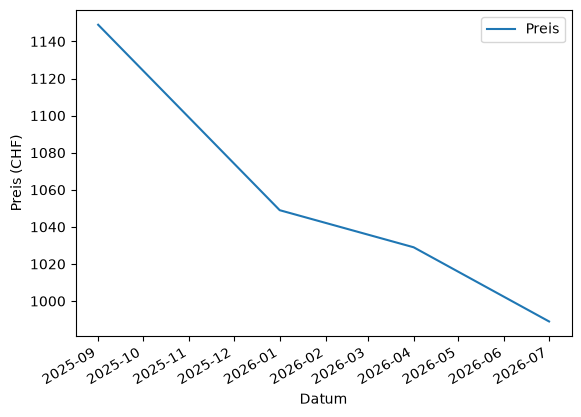

In [120]:
df_C3.plot(kind="line", x="Datum", y="Preis")
plt.xlabel("Datum")
plt.ylabel("Preis (CHF)")

In [107]:
df_C3.info()

<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Datum   5 non-null      datetime64[us]
 1   Preis   5 non-null      str           
dtypes: datetime64[us](1), str(1)
memory usage: 212.0 bytes


---
### Jupyter notebook --footer info-- (please always provide this at the end of each notebook)

In [ ]:
# Libraries
import os, platform, socket
from platform import python_version
from datetime import datetime

# Print system information
print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime('%Y-%m-%d %H:%M:%S'))
print('Python Version:', python_version())
print('IP Address:', socket.gethostbyname(socket.gethostname()))
print('-----------------------------------')